In an article in the Financial Analysts Journal, Ibbotson, Carr and Robinson 
report the following statistics, for the U.S. and British (U.K.) stock markets, 
based on the US dollar performance of stock market indexes for the two 
countries. 

The standard deviation (in percent per year) are 17.7 and 33.6 for the U.S. and 
the U.K., respectively.  The correlation of the two markets was 0.617
Assuming that these statistics remain stable and that expected US dollar rates of 
return to a U.S. investor now are 14 percent in the U.S. market and 20 percent 
in the U.K. market.  U.S. Treasury Bills yield 6 percent.

In [1]:
Sigma_us = 17.7
Sigma_uk = 33.6
cor = 0.617

r_us = 0.14
r_uk = 0.20

rf = 0.06

What is the expected rate of return of a portfolio 50 percent invested in the U.S. 
stock market and 50 percent in the U.K. market?

In [2]:
r_us * 0.5 + r_uk * 0.5

0.17

What is the annual standard deviation of a portfolio 50 percent invested in the 
U.S. stock market and 50 percent in the U.K. market?



In [3]:
x1 = 0.5; x2 = 0.5

import numpy as np
Sigma_portfolio = np.sqrt(x1**2 * Sigma_us**2 + x2**2 * Sigma_uk**2 + 2* x1 * x2 * Sigma_us* Sigma_uk * cor)

print(Sigma_portfolio)

23.324528291050175


Suppose your stock portfolio is now invested entirely in the U.S. 
market but you wonder to what extent international diversification 
makes sense.  More practically, you could invest in any one of the four 
following more or less diversified portfolios 

In [4]:
def Er_and_sigma(r1, r2, cor, points=1000):
    x1 = np.linspace(0, 1, points)
    x2 = 1 - x1

    Er = x1*r1 + x2* r2
    sigma = np.sqrt(x1**2 * Sigma_us**2 + x2**2 * Sigma_uk**2 + 2* x1 * x2 * Sigma_us* Sigma_uk * cor)

    return Er, sigma
    

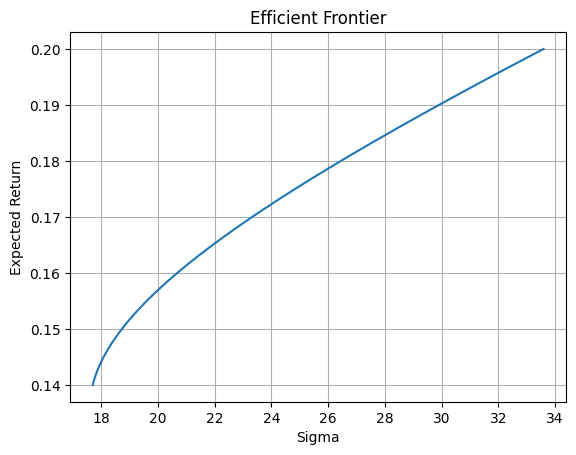

In [5]:
points = 1000
Er, sigma = Er_and_sigma(r_us, r_uk, cor, points=points)

import matplotlib.pyplot as plt
plt.plot(sigma, Er)
plt.xlabel('Sigma')
plt.ylabel('Expected Return')
plt.title('Efficient Frontier')
plt.grid()

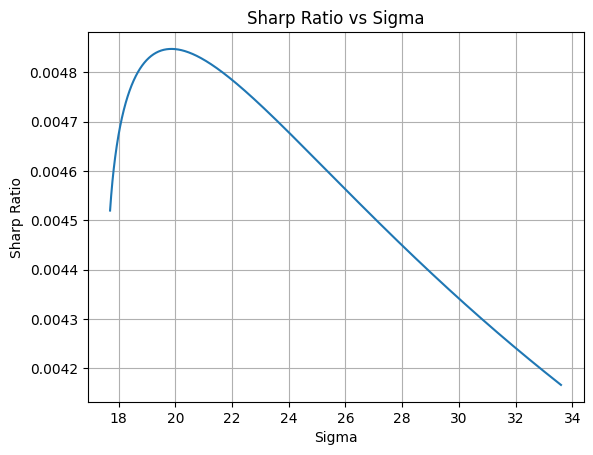

In [6]:
Sharp_ratio = (Er - rf) /sigma 

plt.plot(sigma, Sharp_ratio)
plt.xlabel('Sigma')
plt.ylabel('Sharp Ratio')
plt.title('Sharp Ratio vs Sigma')
plt.grid()

In [ ]:
idx = np.argmax(Sharp_ratio)

selected_sigma = sigma[idx]
selected_Er = Er[idx]
selected_Sharp = Sharp_ratio[idx]

selected_w1 = np.linspace(0, 1, points)[idx]
selected_w2 = 1- selected_w1

print(f"Optimal Weights: US: {selected_w1:.4f}, UK: {selected_w2:.4f}, Sigma: {selected_sigma:.4f}, Expected Return: {selected_Er:.4f}, Sharp Ratio: {selected_Sharp:.4f}")

Optimal Weights: US: 0.7287, UK: 0.2713, Sigma: 19.8627, Expected Return: 0.1563, Sharp Ratio: 0.0048


: 